In [1]:
import pandas as pd
dji = pd.read_csv('DJI.csv')
ufo = pd.read_csv('ufo.csv')

In [2]:
dji.head()

,Date,Value
0,1941,110.96
1,1942,119.40
2,1943,135.89
3,1944,152.32
4,1945,192.91


In [3]:
ufo.head()

,Date,Value
0,1941,1
1,1942,2
2,1943,9
3,1944,9
4,1945,9


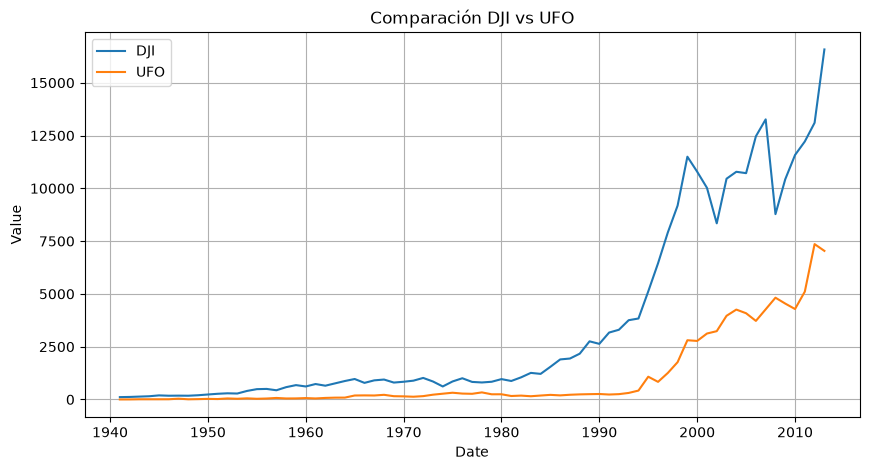

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(dji["Date"], dji["Value"], label="DJI")
plt.plot(ufo["Date"], ufo["Value"], label="UFO")
plt.xlabel("Date")
plt.ylabel("Value")
plt.title("Comparación DJI vs UFO")
plt.legend()
plt.grid(True)
plt.show()

# Correlaciones Espurias

- Dos series con tendencia pueden presentar una alta correlación aún cuando no tinen ninguna relación. (*spurious correlation*) 
- Por ello, en series financieras se analiza la relación de los **rendimientos** y de los **niveles**.

In [5]:
levels = dji.merge(ufo, on="Date", suffixes=("_DJI", "_UFO"))
levels = levels.sort_values(by="Date").reset_index(drop=True)
levels.head()

,Date,Value_DJI,Value_UFO
0,1941,110.96,1
1,1942,119.40,2
2,1943,135.89,9
3,1944,152.32,9
4,1945,192.91,9


## **Cálculo de la correlación**

In [6]:
correlation1 = levels["Value_DJI"].corr(levels["Value_UFO"])
print(f"Correlación entre DJI y UFO: {correlation1:.4f}")

changes = levels.pct_change()
correlation2 = changes["Value_DJI"].corr(changes["Value_UFO"])
print(f"Correlación entre los cambios porcentuales de DJI y UFO: {correlation2:.4f}")   

Correlación entre DJI y UFO: 0.9400
Correlación entre los cambios porcentuales de DJI y UFO: 0.0603


In [7]:
changes.head(20)

,Date,Value_DJI,Value_UFO
0,NaN,NaN,NaN
1,0.000515,0.076063,1.000000
2,0.000515,0.138107,3.500000
3,0.000515,0.120907,0.000000
4,0.000514,0.266478,0.000000
5,0.000514,-0.081437,0.111111
6,0.000514,0.022348,2.700000
7,0.000514,-0.021307,-0.783784
8,0.000513,0.128765,1.000000
9,0.000513,0.176285,0.750000


# Coeficiente de Determinación (R²)
- El **R²** mide que tan bien se ajustan los datos a la recta de regresión.


$$
|\rho_{xy}| = \sqrt{R^2}
$$

In [8]:
import numpy as np
import statsmodels.api as sm

np.random.seed(42)

x = pd.Series(np.random.rand(100), name="x")
y = pd.Series(3*x + np.random.normal(0, 20, 100), name="y")

correlation = x.corr(y)
print(f"Correlación entre x e y: {correlation:.4f}")

X = pd.DataFrame(x)
X = sm.add_constant(X)

model = sm.OLS(y, X)
results = model.fit()

print(results.summary())

Correlación entre x e y: -0.1016
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.022
Date:                Wed, 15 Jul 2026   Prob (F-statistic):              0.315
Time:                        12:31:55   Log-Likelihood:                -430.72
No. Observations:                 100   AIC:                             865.4
Df Residuals:                      98   BIC:                             870.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.30

## Reversión a la Media y Autocorrelación 

In [9]:
msft = pd.read_csv('MSFT.csv')

In [10]:
msft["Date"] = pd.to_datetime(msft["Date"])
msft = msft.set_index("Date")

In [11]:
msft.dtypes

Adj Close    float64
dtype: object

In [12]:
msft = msft.resample(rule='W').last()
returns = msft["Adj Close"].pct_change().dropna()
autocorrelation = returns.autocorr()
print(f"Autocorrelación de los retornos: {autocorrelation:.4f}")

Autocorrelación de los retornos: -0.1568


# Autocorrelación de las Tasas de Interés

In [13]:
daily_rates = pd.read_csv('GS10.csv')
daily_rates.head()

,observation_date,GS10
0,1953-04-01,2.83
1,1953-05-01,3.05
2,1953-06-01,3.11
3,1953-07-01,2.93
4,1953-08-01,2.95


In [14]:
daily_rates.dtypes

observation_date        str
GS10                float64
dtype: object

In [15]:
daily_rates["observation_date"] = pd.to_datetime(daily_rates["observation_date"])
daily_rates = daily_rates.set_index("observation_date")
daily_rates.head()

,GS10
observation_date,
1953-04-01,2.83
1953-05-01,3.05
1953-06-01,3.11
1953-07-01,2.93
1953-08-01,2.95


In [16]:
daily_diff = daily_rates.diff().dropna()
daily_diff.head()

,GS10
observation_date,
1953-05-01,0.22
1953-06-01,0.06
1953-07-01,-0.18
1953-08-01,0.02
1953-09-01,-0.08


In [17]:
autocorrelation_daily_diff = daily_diff["GS10"].autocorr()
print(f"Autocorrelación de los cambios diarios en GS10: {autocorrelation_daily_diff:.4f}")

Autocorrelación de los cambios diarios en GS10: 0.3063


In [18]:
yearly_rates = daily_rates.resample('YE').last()
yearly_diff = yearly_rates.diff().dropna()
autocorrelation_yearly_diff = yearly_diff["GS10"].autocorr()
print(f"Autocorrelación de los cambios anuales en GS10: {autocorrelation_yearly_diff:.4f}")

Autocorrelación de los cambios anuales en GS10: -0.1236


# Función de Autocorrelación

In [19]:
hrb = pd.read_csv('HRB.csv')

In [20]:
hrb.head()

,Quarter,Earnings
0,2007Q1,-0.36
1,2007Q2,-0.38
2,2007Q3,0.07
3,2007Q4,1.85
4,2008Q1,-0.34


In [21]:
hrb["Quarter"] = pd.PeriodIndex(hrb["Quarter"], freq='Q')
hrb = hrb.set_index("Quarter")
hrb.head()

,Earnings
Quarter,
2007Q1,-0.36
2007Q2,-0.38
2007Q3,0.07
2007Q4,1.85
2008Q1,-0.34


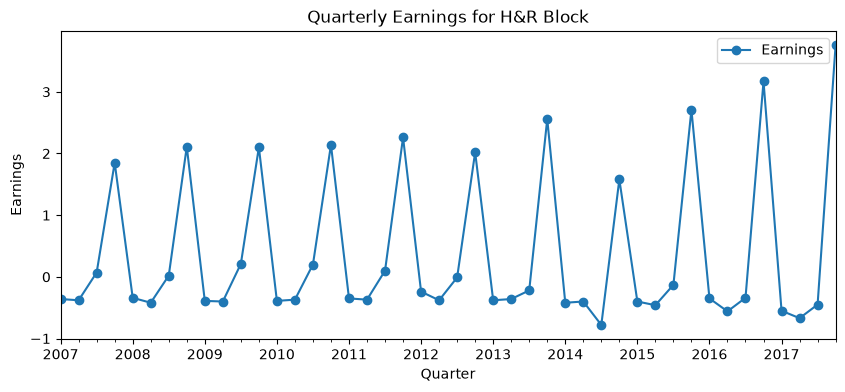

In [22]:
hrb['Earnings'].plot(figsize=(10, 4), marker='o')
plt.title('Quarterly Earnings for H&R Block')
plt.xlabel('Quarter')
plt.ylabel('Earnings')
plt.legend(['Earnings'])
plt.show()

In [23]:
hrb["Earnings"].autocorr(lag=2)

np.float64(-0.44462580750791536)

[ 1.         -0.22122696 -0.39856504 -0.26615093  0.83479804 -0.1901038
 -0.3475634  -0.23140368  0.71995993 -0.15661007 -0.29766783 -0.22097189
  0.61656933 -0.15022869 -0.27922022 -0.22465946  0.5725259 ]


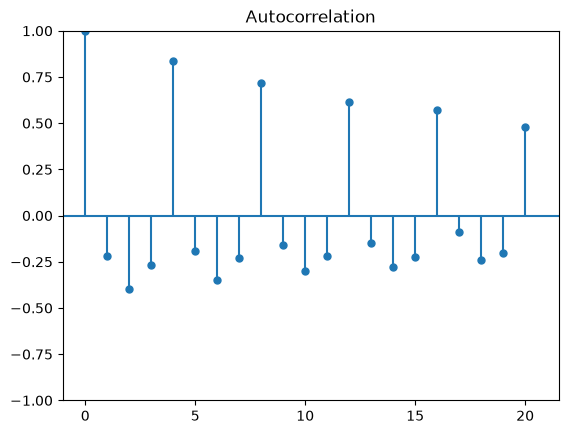

In [24]:
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf

acf_array = acf(hrb["Earnings"])
print(acf_array)
plot_acf(hrb["Earnings"], lags=20, alpha=1)
plt.show()

In [25]:
msft.head()
returns = msft["Adj Close"].pct_change().dropna()
returns.head()

Date
2012-08-19    0.022508
2012-08-26   -0.011003
2012-09-02    0.008508
2012-09-09    0.004218
2012-09-16    0.008400
Freq: W-SUN, Name: Adj Close, dtype: float64

# Significancia de la Autocorrelación

- La autocorrelación muestral puede diferir de cero por efecto del azar.
- Su desviación estándar aproximada es:

$$
\frac{1}{\sqrt{N}}
$$

donde \(N\) es el número de observaciones.

- El intervalo de confianza del 95 % es:

$$
\pm \frac{1.96}{\sqrt{N}}
$$

- En este ejercicio se compara la autocorrelación semanal de MSFT (\(-0.16\)) con este intervalo para determinar si es estadísticamente significativa.

Autocorrelación de los retornos de MSFT: -0.1568
EL intervalo de confianza aproximado es +/- 0.1216


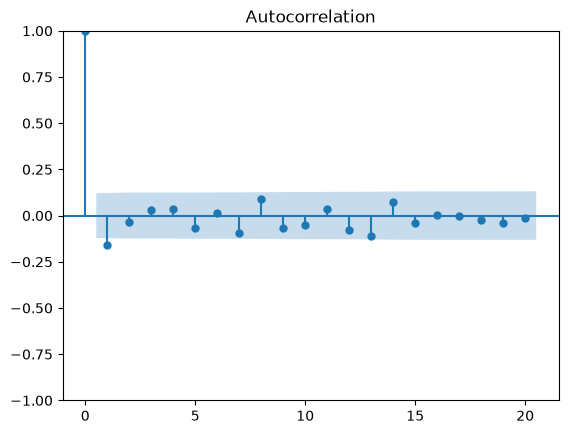

In [26]:
from math import sqrt

autocorrelation_returns = returns.autocorr()
print(f"Autocorrelación de los retornos de MSFT: {autocorrelation_returns:.4f}")
nobs = len(returns)
conf = 1.96/sqrt(nobs)
print(f"EL intervalo de confianza aproximado es +/- {conf:.4f}")
plot_acf(returns, lags=20, alpha=0.05)
plt.show()

# Ruido Blanco

- Media Constante
- Varianza Constante
- Autocorrelación casi igual a cero todos los rezagos

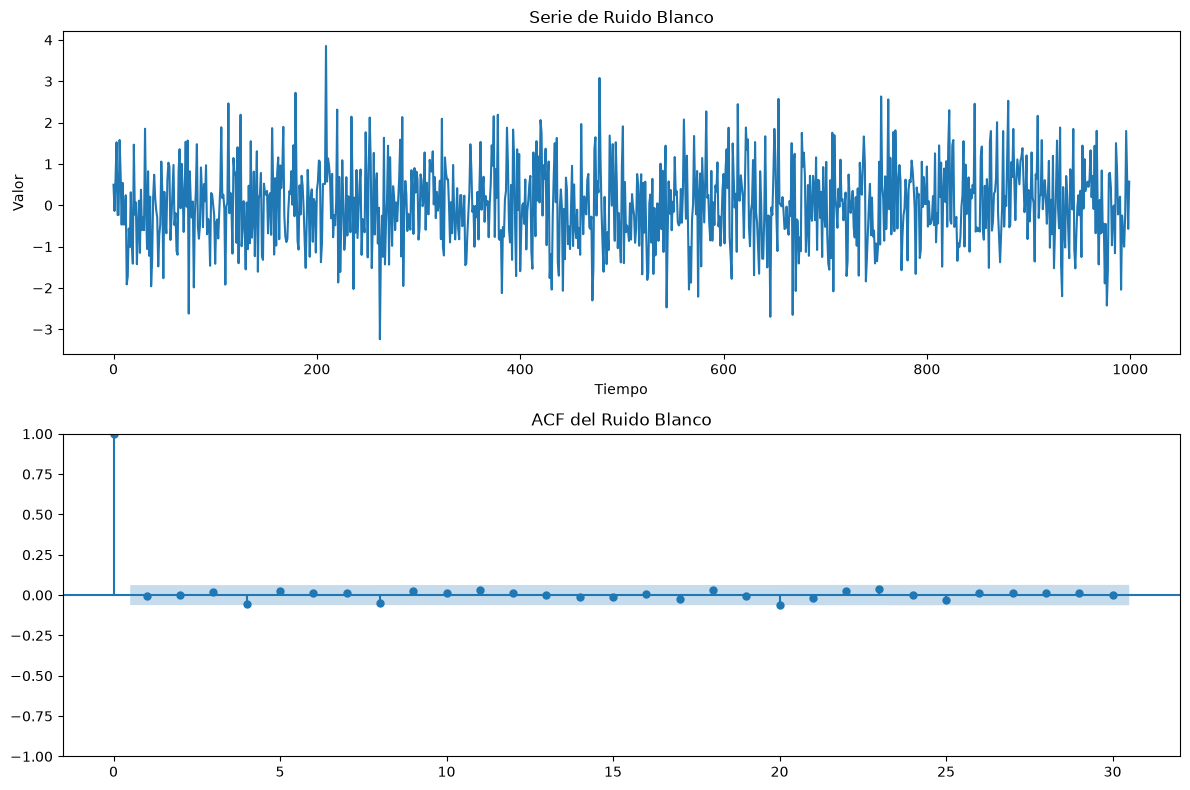

In [27]:
np.random.seed(42)

white_noise = np.random.normal(0, 1, 1000)

# Crear la figura con dos gráficos
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

# Serie de tiempo
ax[0].plot(white_noise)
ax[0].set_title('Serie de Ruido Blanco')
ax[0].set_xlabel('Tiempo')
ax[0].set_ylabel('Valor')

# Función de autocorrelación
plot_acf(white_noise, lags=30, alpha=0.05, ax=ax[1])
ax[1].set_title('ACF del Ruido Blanco')

plt.tight_layout()
plt.show()



# Caminata aleatoria (Random Walk)


- Un **Random Walk** cumple:

```text
Precio_t = Precio_{t-1} + ruido


- Los **cambios en el precio** (o retornos) son **Ruido Blanco**.

- Un **Random Walk con drift** incluye una tendencia promedio:

```text
Precio_t = Precio_{t-1} + μ + ruido

### Prueba de Random Walk: Dickey-Fuller

- **Hipótesis nula (H₀):** la serie tiene una raíz unitaria y sigue un Random Walk.
- **Hipótesis alternativa (H₁):** la serie es estacionaria.

```python
from statsmodels.tsa.stattools import adfuller

result = adfuller(serie)
p_value = result[1]
```

### Interpretación del p-value

- `p-value < 0.05` → Se rechaza H₀ → La serie **no** es un Random Walk.
- `p-value ≥ 0.05` → No se rechaza H₀ → La serie **puede ser** un Random Walk.

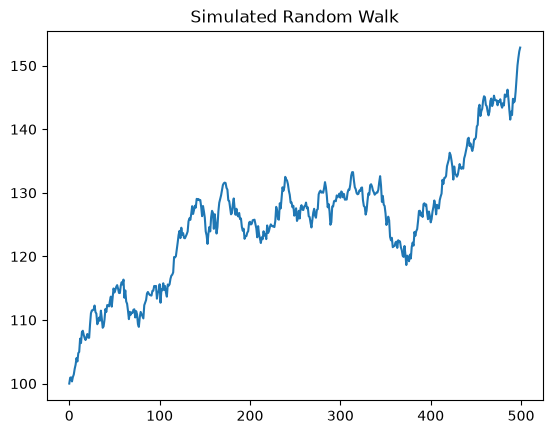

In [28]:
# Generate 500 random steps with mean=0 and standard deviation=1
steps = np.random.normal(loc=0, scale=1, size=500)

# Set first element to 0 so that the first price will be the starting stock price
steps[0]=0

# Simulate stock prices, P with a starting price of 100
P = 100 + np.cumsum(steps)

# Plot the simulated stock prices
plt.plot(P)
plt.title("Simulated Random Walk")
plt.show()

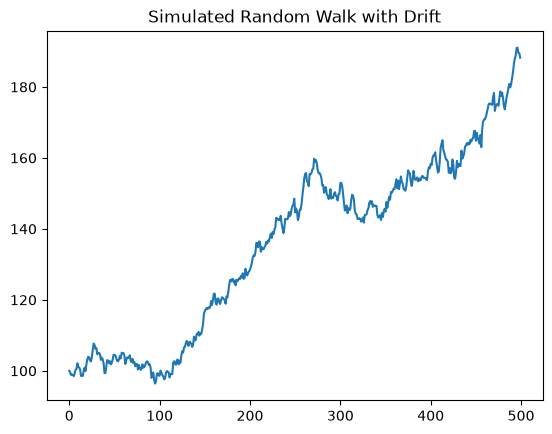

In [29]:
# Generate 500 random steps 
steps = np.random.normal(loc=0.001, scale=0.01, size=500) + 1

# Set first element to 1
steps[0]=1

# Simulate the stock price, P, by taking the cumulative product
P = 100 * np.cumprod(steps)

# Plot the simulated stock prices
plt.plot(P)
plt.title("Simulated Random Walk with Drift")
plt.show()

### ¿Los precios de las acciones siguen una caminata aleatoria?

In [30]:
amzn = pd.read_csv('AMZN.csv')
amzn.head()

,Date,Adj Close
0,5/15/1997,1.958333
1,5/16/1997,1.729167
2,5/19/1997,1.708333
3,5/20/1997,1.635417
4,5/21/1997,1.427083


In [31]:
from statsmodels.tsa.stattools import adfuller

results = adfuller(amzn["Adj Close"])
print(results)

print("El p-valor del test ADF es:", results[1])

(np.float64(4.025168525770739), 1.0, 33, 5054, {'1%': np.float64(-3.4316445438146865), '5%': np.float64(-2.862112049726916), '10%': np.float64(-2.5670745025321304)}, np.float64(30308.64216426981))
El p-valor del test ADF es: 1.0


In [32]:
amzn["Date"] = pd.to_datetime(amzn["Date"])
amzn = amzn.set_index("Date")
amzn_ret = amzn.pct_change().dropna()

results_ret = adfuller(amzn_ret["Adj Close"])
print("El p-valor del test ADF para los retornos es:", results_ret[1])

El p-valor del test ADF para los retornos es: 2.565589808347901e-22


### Stationarity (Estacionariedad)

Una serie es **débilmente estacionaria** si:

- La **media** es constante.
- La **varianza** es constante.
- Las **autocorrelaciones** dependen solo del rezago y no del tiempo.

### ¿Por qué es importante?

La estacionariedad permite construir **modelos parsimoniosos**, es decir, con pocos parámetros y estables en el tiempo.

### Ejemplos de series no estacionarias

- **Random Walk:** la varianza crece con el tiempo.
- **Series estacionales:** la media cambia periódicamente.
- **Series con tendencia:** la media cambia con el tiempo.

### Cómo transformar una serie en estacionaria

- **Primera diferencia** (`X_t - X_{t-1}`):
  - Convierte un Random Walk en una serie estacionaria.

- **Diferencia estacional** (`X_t - X_{t-s}`):
  - Elimina la estacionalidad.

- **Logaritmo + diferencias**:
  - Elimina crecimiento exponencial y estacionalidad.

En muchos casos, una o varias de estas transformaciones permiten convertir una serie no estacionaria en una serie estacionaria.

## Ejercicio: ¿Cuál de las siguientes series es estacionaria?

La figura muestra cuatro series de tiempo simuladas (A, B, C y D).

**Pregunta:** Identifique cuál(es) de las series son estacionarias y justifique su respuesta.

Recuerde que una serie es **estacionaria** si cumple las siguientes propiedades:

- La **media** es aproximadamente constante en el tiempo.
- La **varianza** es aproximadamente constante en el tiempo.
- No presenta **tendencia** ni patrones sistemáticos.

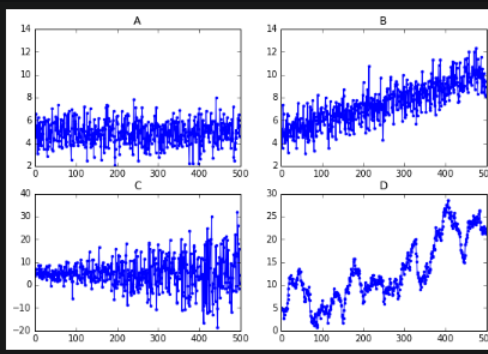

### Opciones

- a) Solo la serie **A** es estacionaria.
- b) Las series **A** y **C** son estacionarias.
- c) Las series **B** y **D** son estacionarias.
- d) Ninguna de las series es estacionaria.

### Ajuste Estacional

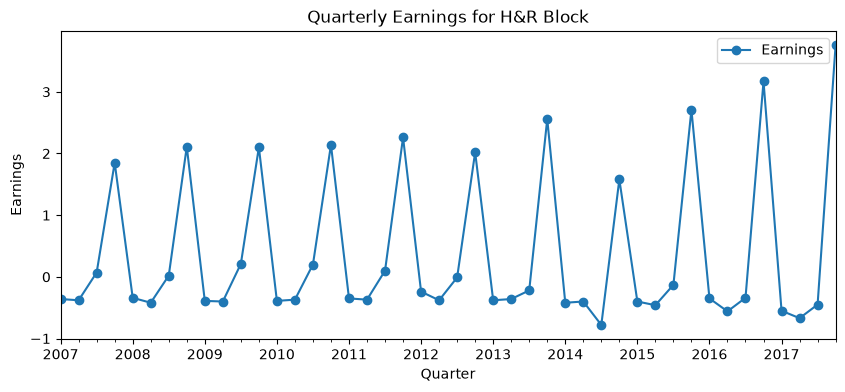

In [33]:
hrb['Earnings'].plot(figsize=(10, 4), marker='o')
plt.title('Quarterly Earnings for H&R Block')
plt.xlabel('Quarter')
plt.ylabel('Earnings')
plt.legend(['Earnings'])
plt.show()

[ 1.         -0.22122696 -0.39856504 -0.26615093  0.83479804 -0.1901038
 -0.3475634  -0.23140368  0.71995993 -0.15661007 -0.29766783 -0.22097189
  0.61656933 -0.15022869 -0.27922022 -0.22465946  0.5725259 ]


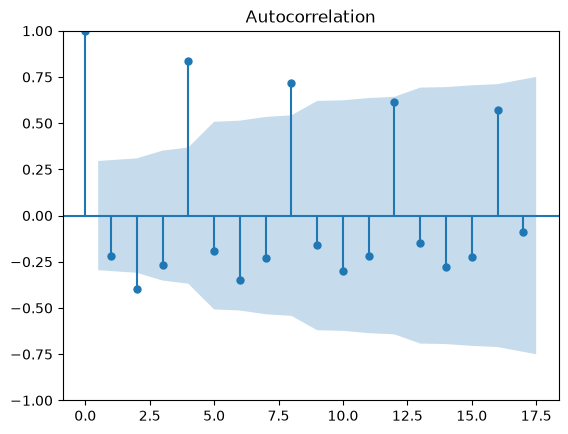

In [34]:
hrb.head()

# Compute the acf array
acf_array = acf(hrb["Earnings"])
print(acf_array)

# Plot the acf
plot_acf(hrb["Earnings"], alpha=0.05)
plt.show()

         Earnings
Quarter          
2008Q1       0.02
2008Q2      -0.04
2008Q3      -0.05
2008Q4       0.26
2009Q1      -0.05
2009Q2       0.02
2009Q3       0.19
2009Q4      -0.01
2010Q1       0.00
2010Q2       0.03


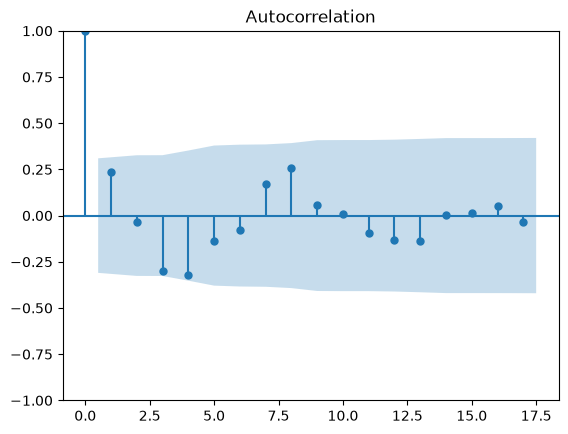

In [35]:
hrbae = hrb.diff(4).dropna()
print(hrbae.head(10))
plot_acf(hrbae)
plt.show()

Text(0, 0.5, 'Seasonally Adjusted Earnings')

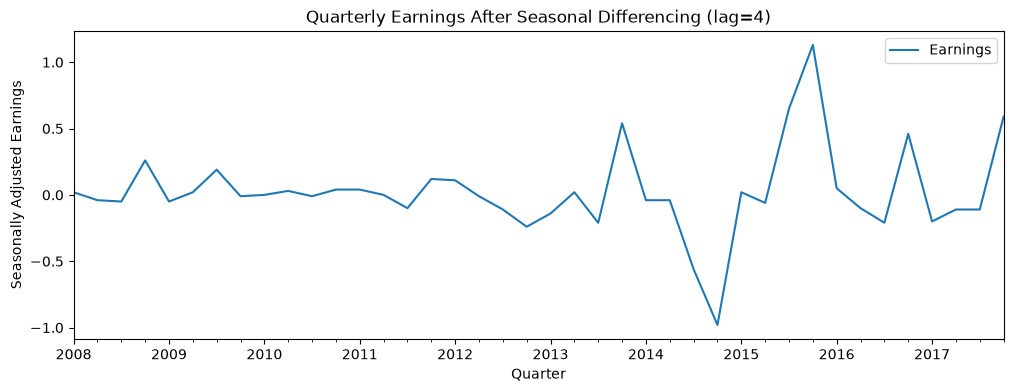

In [36]:
# Graficar la serie transformada
fig, ax = plt.subplots(figsize=(12, 4))

hrbae.plot(ax=ax)

ax.set_title('Quarterly Earnings After Seasonal Differencing (lag=4)')
ax.set_xlabel('Quarter')
ax.set_ylabel('Seasonally Adjusted Earnings')

### Modelo Autorregresivo AR(p)

En un modelo **Autorregresivo (AR)**, el valor actual depende de sus valores pasados y de un término de ruido.

#### Modelo AR(1)

```text
X_t = μ + φ X_{t-1} + ε_t
```

donde:

- `μ` = media de la serie.
- `φ` = parámetro autorregresivo.
- `ε_t` = ruido blanco.

#### Interpretación de `φ`

- `φ = 1` → Random Walk.
- `φ = 0` → Ruido Blanco.
- `-1 < φ < 1` → Serie estacionaria.
- `φ > 0` → Persistencia o **momentum**.
- `φ < 0` → **Reversión a la media (mean reversion)**.

#### Comportamiento de la ACF

- La ACF de un AR(1) **decrece exponencialmente**:

```text
ρ_k = φ^k
```

- Si `φ < 0`, las autocorrelaciones **alternan de signo**.

#### Modelos de orden superior

- **AR(1):** depende de `X_{t-1}`.
- **AR(2):** depende de `X_{t-1}` y `X_{t-2}`.
- **AR(3):** depende de los tres últimos valores.

#### Simulación en Python

Se puede simular un proceso AR usando:

```python
from statsmodels.tsa.arima_process import ArmaProcess
```

y generar muestras con:

```python
ar_process.generate_sample(nsample)
```

### Simulación de un AR(1)

- Un proceso **AR(1)** puede simularse con `ArmaProcess` de `statsmodels`.

- Para un AR(1) con parámetro `φ`, se define:

```python
ar = np.array([1, -φ])
ma = np.array([1])
```

> **Nota:** el signo de `φ` se ingresa con el signo opuesto.

- Crear el proceso:

```python
AR_object = ArmaProcess(ar, ma)
```

- Generar datos simulados:

```python
simulated_data = AR_object.generate_sample(nsample=1000)
```

- Al variar `φ`, cambia el comportamiento de la serie:
  - `φ > 0` → mayor persistencia.
  - `φ < 0` → oscilaciones y reversión a la media.

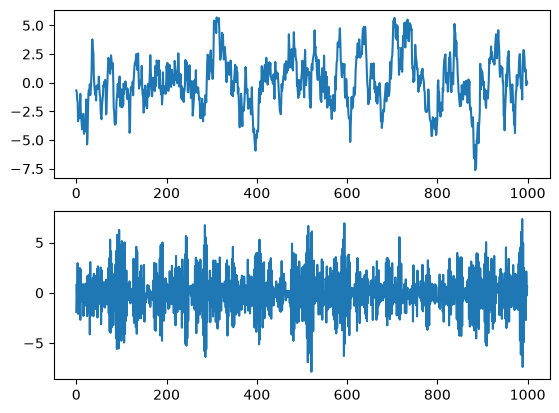

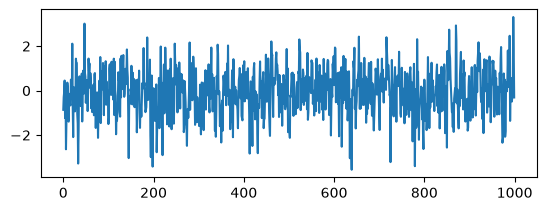

In [37]:
from statsmodels.tsa.arima_process import ArmaProcess

# Plot 1: AR parameter = +0.9
plt.subplot(2,1,1)
ar1 = np.array([1, -0.9])
ma1 = np.array([1])
AR_object1 = ArmaProcess(ar1, ma1)
simulated_data_1 = AR_object1.generate_sample(nsample=1000)
plt.plot(simulated_data_1)

# Plot 2: AR parameter = -0.9
plt.subplot(2,1,2)
ar2 = np.array([1, 0.9])
ma2 = np.array([1])
AR_object2 = ArmaProcess(ar2, ma2)
simulated_data_2 = AR_object2.generate_sample(nsample=1000)
plt.plot(simulated_data_2)
plt.show()

# Plot 3: AR parameter = 0.3
plt.subplot(2,1,2)
ar3 = np.array([1, -0.3])
ma3 = np.array([1])
AR_object3 = ArmaProcess(ar3, ma3)
simulated_data_3 = AR_object3.generate_sample(nsample=1000)
plt.plot(simulated_data_3)
plt.show()


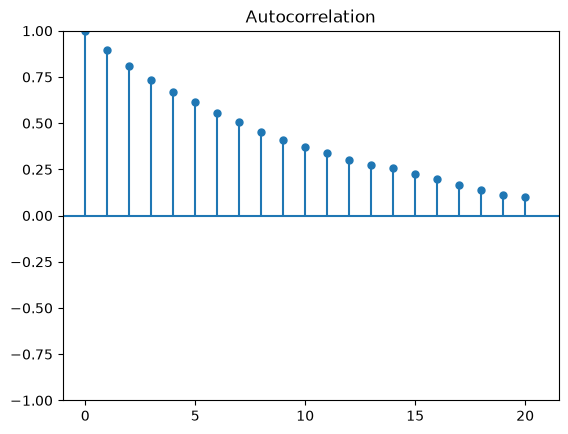

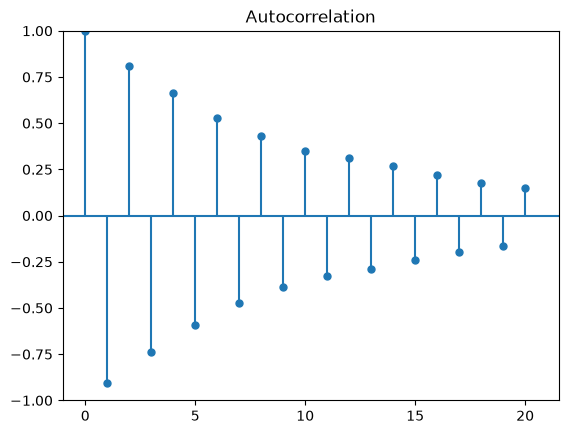

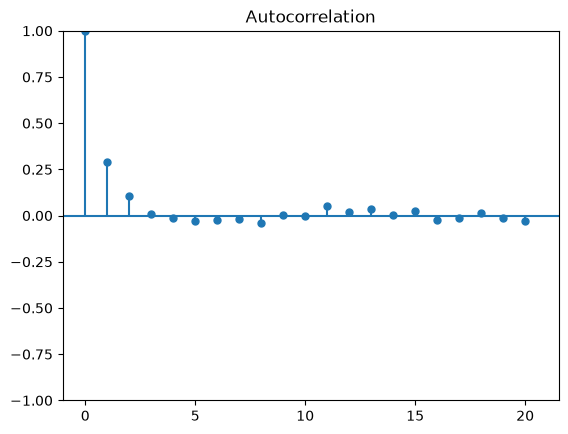

In [38]:
plot_acf(simulated_data_1, lags=20, alpha=1)
plt.show()

plot_acf(simulated_data_2, lags=20, alpha=1)
plt.show()

plot_acf(simulated_data_3, lags=20, alpha=1)
plt.show()

### Pregunta

Observe las siguientes funciones de autocorrelación (ACF).

**¿Cuál de las figuras corresponde a un modelo AR(1) con un parámetro autorregresivo `φ = -0.5`?**

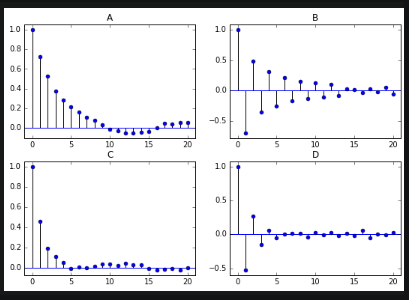

### Estimación y Pronóstico de un modelo autorregresivo

```python
from statsmodels.tsa.arima.model import ARIMA

mod = ARIMA(data, order=(p, d, q))
result = mod.fit()
```


In [39]:
from statsmodels.tsa.arima.model import ARIMA

mod = ARIMA(simulated_data_1, order=(1,0,0))
res = mod.fit()

print(res.summary())

print("El valor real de phi es 0.9 para los datos simulados, y el estimado de phi es:", res.params[1])

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1000
Model:                 ARIMA(1, 0, 0)   Log Likelihood               -1402.384
Date:                Wed, 15 Jul 2026   AIC                           2810.768
Time:                        12:31:57   BIC                           2825.492
Sample:                             0   HQIC                          2816.364
                               - 1000                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0558      0.304      0.184      0.854      -0.540       0.652
ar.L1          0.8977      0.014     64.449      0.000       0.870       0.925
sigma2         0.9658      0.042     23.256      0.0

### Pronóstico con un modelo AR(1)

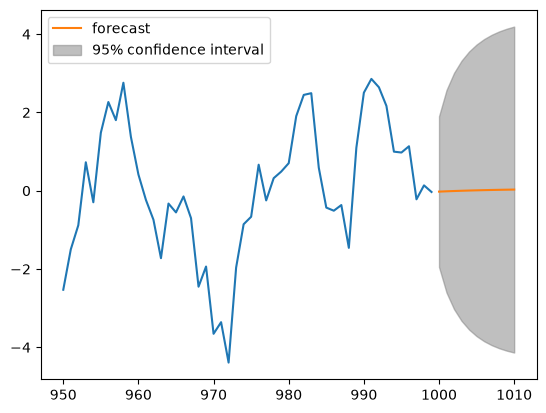

In [40]:
from statsmodels.graphics.tsaplots import plot_predict 

simulated_data_1 = pd.Series(simulated_data_1)
simulated_data_1

mod = ARIMA(simulated_data_1, order=(1,0,0))
res = mod.fit()

fig, ax = plt.subplots()
simulated_data_1.loc[950:].plot(ax=ax)
plot_predict(res, start=1000, end=1010, ax=ax)
plt.show()


### Pronóstico de tasas de interés con un modelo AR(1)

In [41]:
datos_tasas_interes = daily_rates.loc['1962-10-30':'2017-06-21'].resample(rule='YE').last()
datos_tasas_interes.head()

,GS10
observation_date,
1962-12-31,3.86
1963-12-31,4.13
1964-12-31,4.18
1965-12-31,4.62
1966-12-31,4.84


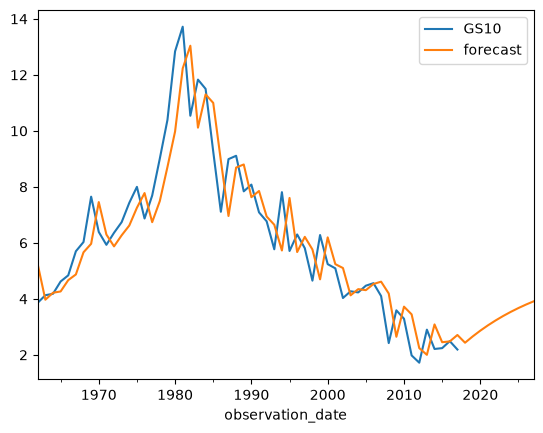

In [42]:
mod = ARIMA(datos_tasas_interes, order=(1,0,0)) # instanciar el modelo
res = mod.fit() # ajustar el modelo a los datos

# Plot the data and the forecast
fig, ax = plt.subplots()
datos_tasas_interes.plot(ax=ax)
plot_predict(res, start=0, end='2027', alpha=None, ax=ax)
plt.show()



### Selección del orden de un modelo autorregresivo AR
Nos vamos a ayudar de dos heramientas!
- PACF (Función de autocorrelación Parcial)
- Criterios de información

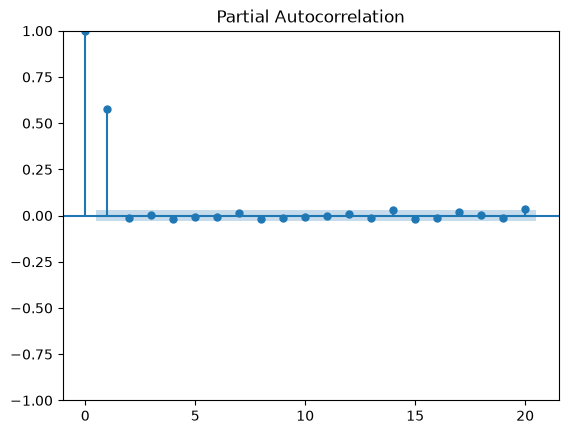

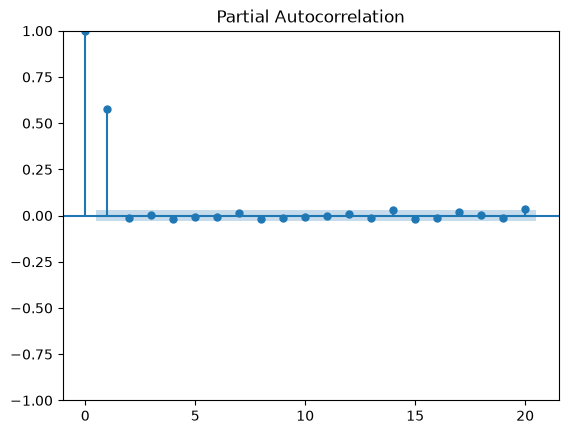

In [43]:
from statsmodels.graphics.tsaplots import plot_pacf

# Simulate AR(1) with phi=+0.6
ma = np.array([1])
ar = np.array([1, -0.6])
AR_object = ArmaProcess(ar, ma)
simulated_data_1 = AR_object.generate_sample(nsample=5000)

plot_pacf(simulated_data_1, lags=20, alpha=0.05)

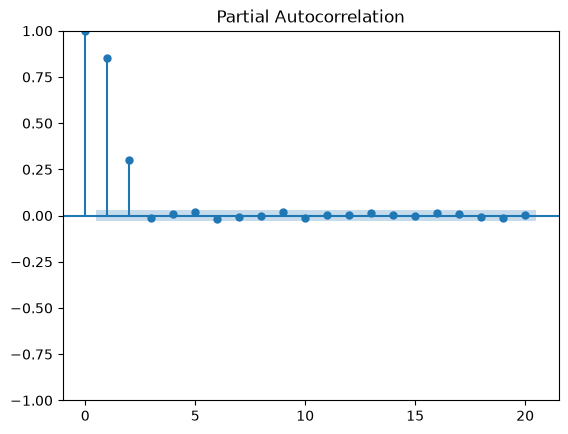

In [44]:
# Simulate AR(2) with phi1=+0.6, phi2=+0.3
ma = np.array([1])
ar = np.array([1, -0.6, -0.3])
AR_object = ArmaProcess(ar, ma)
simulated_data_4 = AR_object.generate_sample(nsample=5000)


# Plot PACF for AR(2)
plot_pacf(simulated_data_4, lags=20)
plt.show()

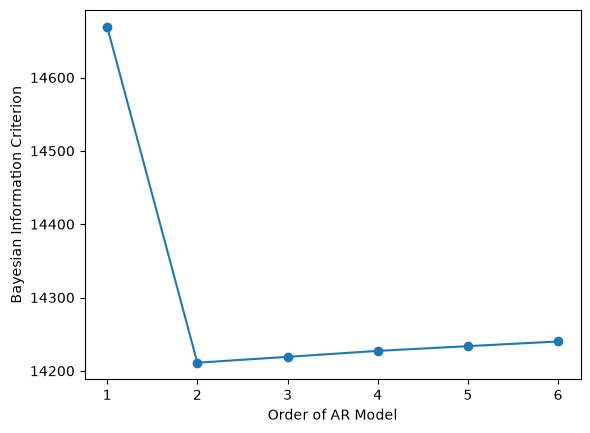

In [45]:
# Import the module for estimating an ARIMA model
from statsmodels.tsa.arima.model import ARIMA

# Fit the data to an AR(p) for p = 0,...,6 , and save the BIC
BIC = np.zeros(7)
for p in range(7):
    mod = ARIMA(simulated_data_4, order=(p,0,0))
    res = mod.fit()
# Save BIC for AR(p)    
    BIC[p] = res.bic
    
# Plot the BIC as a function of p
plt.plot(range(1,7), BIC[1:7], marker='o')
plt.xlabel('Order of AR Model')
plt.ylabel('Bayesian Information Criterion')
plt.show()

Determinar el modelo AR
Determinar el modelo MA
Determinar el modelo ARMA
Determinar el modelo ARIMA
Determinar el modelo SARIMA
Determinar el modelo SARIMAX